# Heart Disease Mortality Prediction Pipeline
## Jett Guitteau
### This project is a self-guided part of a learning experience at Qualees to explore machine learning methods and compare a local python machine learning pipeline with their TweenMe platform which can augment data to enhance model performance.

This project utilizes a dataset that includes medical record data of 299 heart failure patients in an attempt to predict mortality based on 11 features. The data was originally used in a research study which aimed at determining machine learning's ability to make these predictions. This project will not replicate the study, but the study contains useful information about the data, such as the origin of the data. 

The features of the dataset include demographic information age and sex; lab values includes creatinine kinase, ejection fraction, platelets, serum creatinine, and serum sodium; and comorbidities such as diabetes, high blood pressure, anemia, and whether the patient has a smoking history. The target column is "death_event" which tracks if the patient died in the time they were followed by the researchers. The original dataset contains a "time" column, which was excluded from the original study and will therefore be omitted from this project as well. 

The dataset can be found on the UC Irvine Machine Learning Repository: https://archive.ics.uci.edu/dataset/519/heart+failure+clinical+records
The original article utilizing this dataset can be found here: https://link.springer.com/article/10.1186/s12911-020-1023-5

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import RidgeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    balanced_accuracy_score,
    matthews_corrcoef,
    log_loss
)

In [48]:
heart = pd.read_csv("heart_failure_clinical_records_dataset.csv")
heart.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,1


In [49]:
heart.info()

<class 'pandas.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(9)
memory usage: 28.2 KB


In [50]:
heart.anaemia = heart.anaemia.astype('category')
heart.diabetes = heart.diabetes.astype('category')
heart.high_blood_pressure = heart.high_blood_pressure.astype('category')
heart.sex = heart.sex.astype('category')
heart.smoking = heart.smoking.astype('category')
heart.DEATH_EVENT = heart.DEATH_EVENT.astype('category')

In [51]:
heart.dtypes

age                          float64
anaemia                     category
creatinine_phosphokinase       int64
diabetes                    category
ejection_fraction              int64
high_blood_pressure         category
platelets                    float64
serum_creatinine             float64
serum_sodium                   int64
sex                         category
smoking                     category
DEATH_EVENT                 category
dtype: object

In [52]:
heart.describe()

,age,creatinine_phosphokinase,ejection_fraction,platelets,serum_creatinine,serum_sodium
count,299.000000,299.000000,299.000000,299.000000,299.00000,299.000000
mean,60.833893,581.839465,38.083612,263358.029264,1.39388,136.625418
std,11.894809,970.287881,11.834841,97804.236869,1.03451,4.412477
min,40.000000,23.000000,14.000000,25100.000000,0.50000,113.000000
25%,51.000000,116.500000,30.000000,212500.000000,0.90000,134.000000
50%,60.000000,250.000000,38.000000,262000.000000,1.10000,137.000000
75%,70.000000,582.000000,45.000000,303500.000000,1.40000,140.000000
max,95.000000,7861.000000,80.000000,850000.000000,9.40000,148.000000


In [53]:
heart[heart["serum_sodium"] == 113] # Investigating suspicious value in serum_sodium column

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,DEATH_EVENT
199,60.0,0,1211,1,35,0,263358.03,1.8,113,1,1,0


In [54]:
heart.serum_sodium.value_counts(sort=False).sort_index().head(10) # Investigating suspicious values in serum_sodium column

serum_sodium
113    1
116    1
121    1
124    1
125    1
126    1
127    3
128    2
129    2
130    9
Name: count, dtype: int64

In [55]:
heart.creatinine_phosphokinase.value_counts(sort=False).sort_index(ascending=False).head(10)

creatinine_phosphokinase
7861    1
7702    1
5882    1
5209    1
4540    1
3966    1
3964    1
2794    1
2695    1
2656    1
Name: count, dtype: int64

In [56]:
heart.nlargest(2, 'creatinine_phosphokinase') # Investigating the rows with the highest values of creatinine_phosphokinase. 

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,DEATH_EVENT
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,1
60,45.0,0,7702,1,25,1,390000.00,1.0,139,1,0,1


In [57]:
heart[heart["serum_creatinine"] == 9.4] # Investigating suspicious value in serum_creatinine column

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,DEATH_EVENT
9,80.0,1,123,0,35,1,388000.0,9.4,133,1,1,1


In [58]:
heart.serum_creatinine.value_counts(sort=False).sort_index(ascending=False).head(10)

serum_creatinine
9.4    1
9.0    1
6.8    1
6.1    1
5.8    1
5.0    1
4.4    1
4.0    1
3.8    1
3.7    1
Name: count, dtype: int64

The three investigated lab values here were ones that showed notable extreme values in `heart.describe()`, but as we see they are not the same patient. Investigating the 10 most extreme values in their respective directions we can see many abnormal values, which are all possible and indicate comorbidities (such as kidney failure in the cases of high serum creatinine) or acute events (such as a potential myocardial infarction for the elevated creatinine phosphokinase), which are expected in a patient population such as this one. As these are possible values, and as it's a well known dataset from a peer reviewed study, they are likely true values. Additionally, they are likely influential on the target and will be useful for the models. Both records with the highest creatinine phosphokinase values have DEATH_EVENT = 1. This is a descriptive observation only and the values were retained based on data validity and clinical plausibility, not their outcomes. 

In [59]:
heart.isna().sum() # No missing values in the dataset

age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
DEATH_EVENT                 0
dtype: int64

In [60]:
heart.duplicated().sum() # Check for duplicate rows in the dataset

np.int64(0)

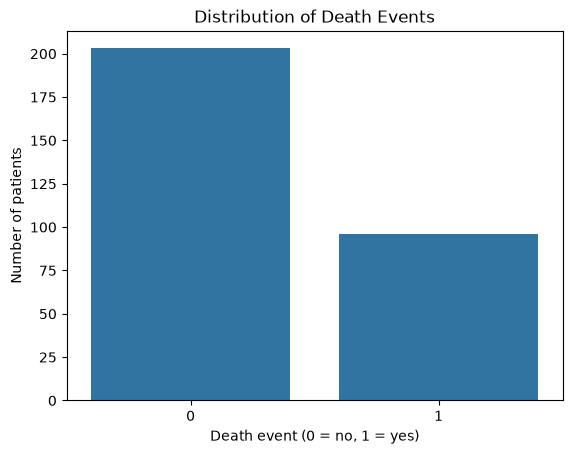

<Figure size 640x480 with 0 Axes>

In [61]:
# Creating a count plot for the distribution of death events
sns.countplot(data=heart, x="DEATH_EVENT")
plt.title("Distribution of Death Events")
plt.xlabel("Death event (0 = no, 1 = yes)")
plt.ylabel("Number of patients")
plt.show()
plt.clf()

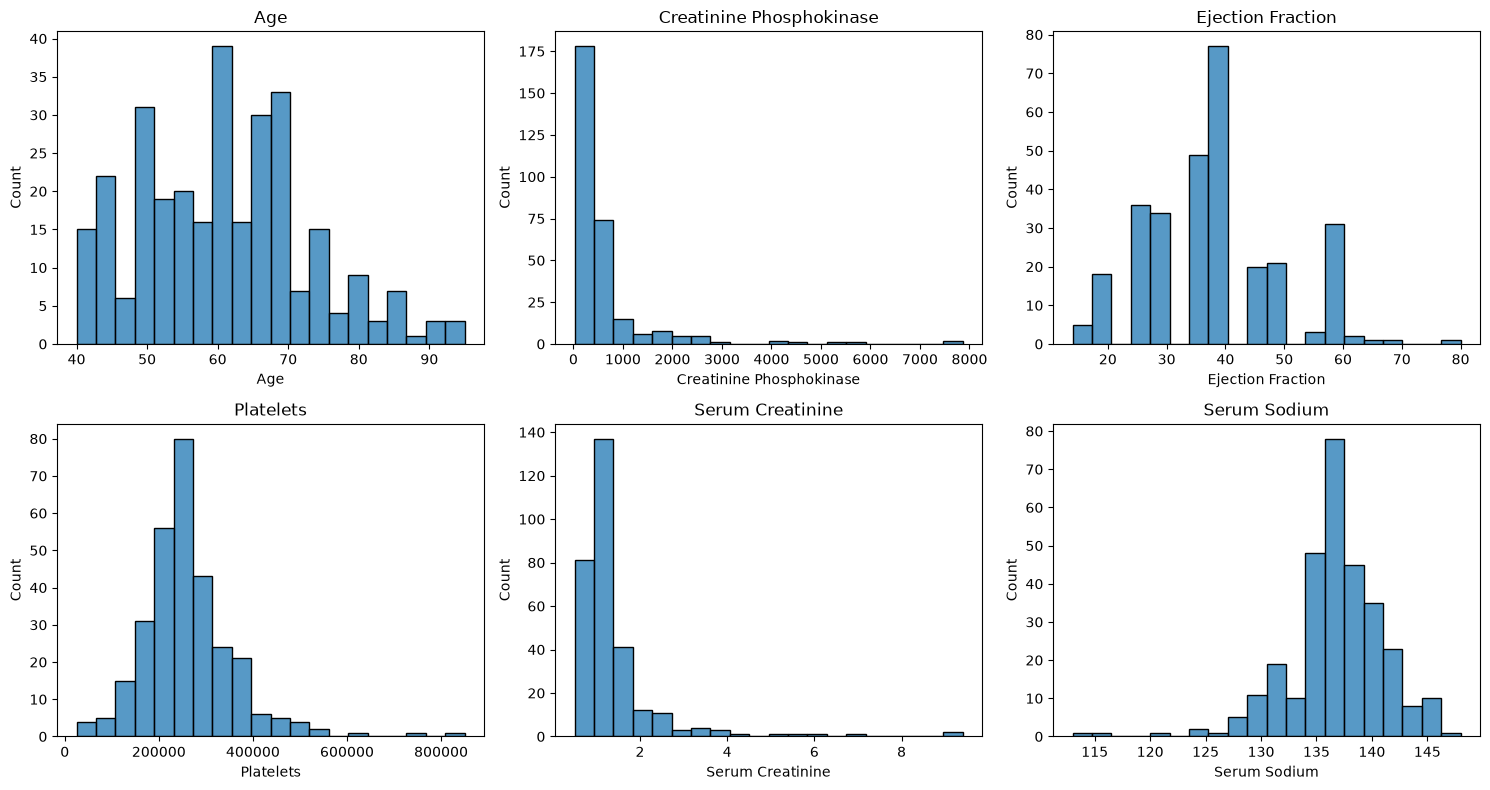

<Figure size 640x480 with 0 Axes>

In [62]:
# Visualizing the distribution of numeric columns
numeric_cols = [
    "age",
    "creatinine_phosphokinase",
    "ejection_fraction",
    "platelets",
    "serum_creatinine",
    "serum_sodium"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for column, ax in zip(numeric_cols, axes.flat):
    sns.histplot(data=heart, x=column, bins=20, ax=ax)
    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()
plt.clf()

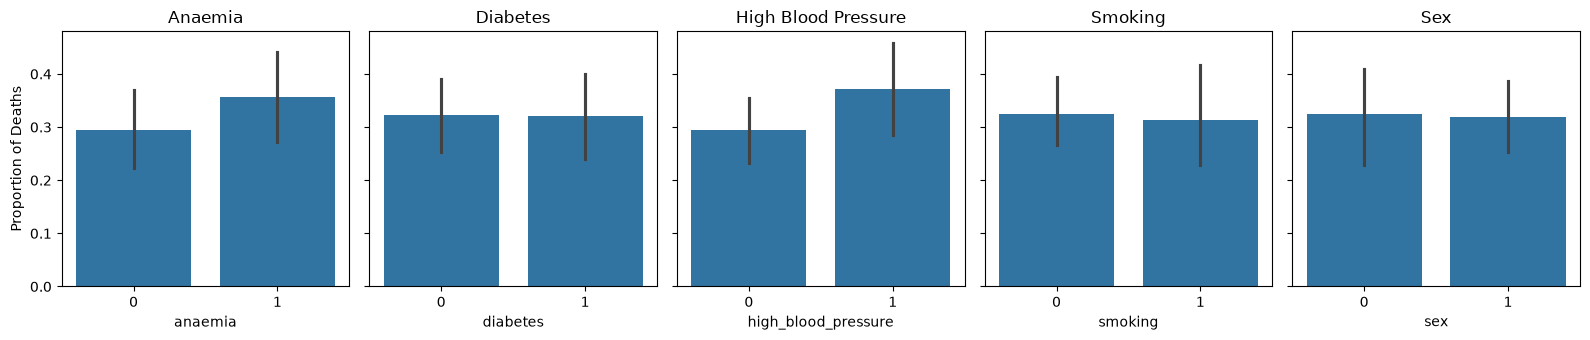

<Figure size 640x480 with 0 Axes>

In [64]:
binary_cols = ["anaemia", "diabetes", "high_blood_pressure", "smoking", "sex"]
plot_data = heart.assign(DEATH_EVENT=heart["DEATH_EVENT"].astype(int))

fig, axes = plt.subplots(1, len(binary_cols), figsize=(16, 3.5), sharey=True)

for ax, col in zip(axes, binary_cols):
    sns.barplot(x=col, y="DEATH_EVENT", data=plot_data, ax=ax)
    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel(col)
    ax.set_ylabel("Proportion of Deaths")

plt.tight_layout()
plt.show()
plt.clf()

Observed differences in death proportions between groups are small relative to their uncertainty. The error bars show bootstrap 95% confidence intervals for each group's estimated death proportion, not measurement error. Overlap between these intervals does not establish that there is no association; these plots alone do not establish whether an association exists.

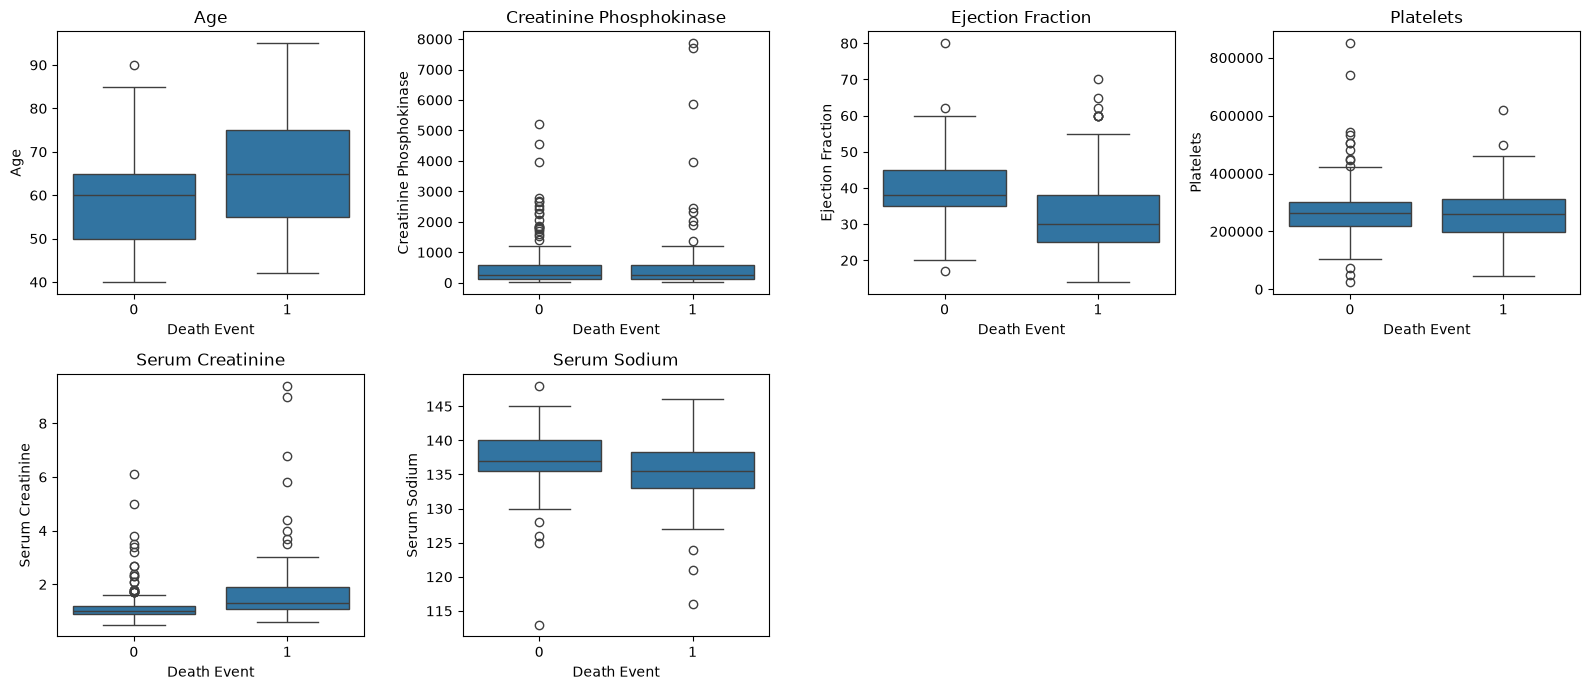

<Figure size 640x480 with 0 Axes>

In [71]:
num_cols = ["age", "creatinine_phosphokinase", "ejection_fraction",
            "platelets", "serum_creatinine", "serum_sodium"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    sns.boxplot(x="DEATH_EVENT", y=col, data=heart, ax=ax)
    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("Death Event")
    ax.set_ylabel(col.replace("_", " ").title())

# hide the unused 8th panel
for ax in axes[len(num_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()
plt.clf()

The graphs show us that there are more noticable relationships between the values of the numeric columns and which are more associated with deaths. Notably, older age, lower ejection fraction, and higher serum creatinine seem suspicious.

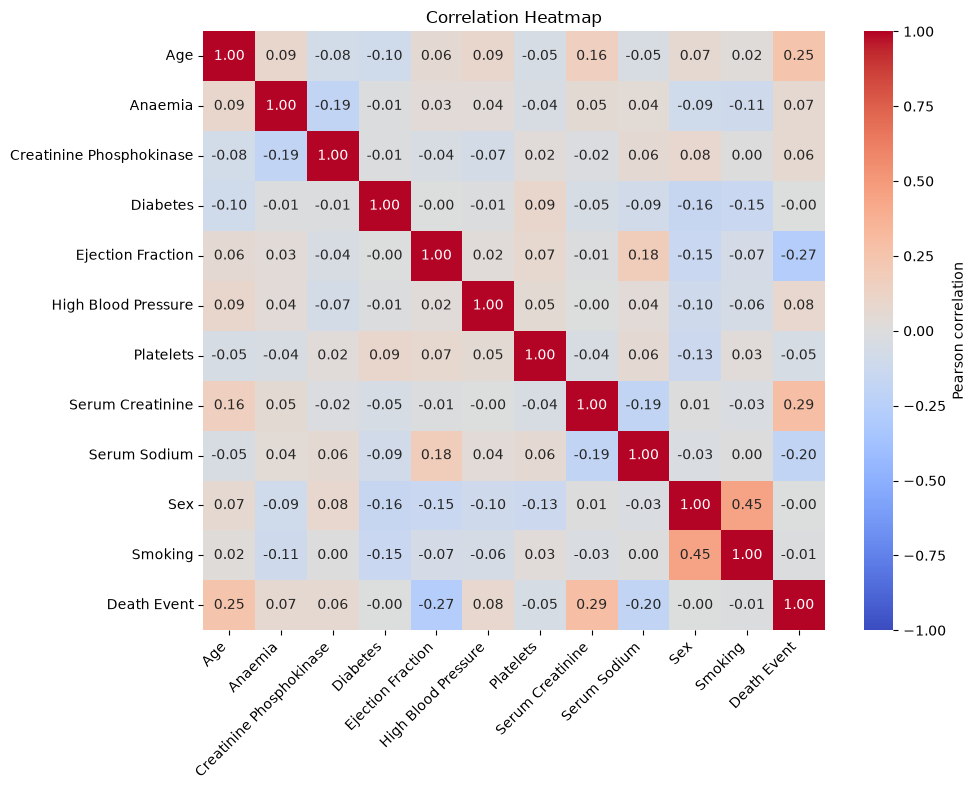

<Figure size 640x480 with 0 Axes>

In [77]:
corr = heart.corr(numeric_only=False)

pretty = lambda s: s.replace("_", " ").title()
corr = corr.rename(index=pretty, columns=pretty)

plt.figure(figsize=(10, 8))
ax = sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1, vmax=1,
    cbar_kws={"label": "Pearson correlation"},
)
ax.set_title("Correlation Heatmap")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()
plt.clf()

The largest absolute pairwise Pearson correlation among the predictors is approximately 0.45, between sex and smoking. No strong pairwise linear correlations are apparent, but this alone does not rule out multicollinearity involving several predictors or nonlinear relationships. Correlations with DEATH_EVENT describe associations with the target, not collinearity among predictors.